In [1]:
# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    roc_curve,
    roc_auc_score
)

# Load cleaned dataset from GitHub

url = "https://raw.githubusercontent.com/anjaliumesh477/Python-Apprentice-Internship/main/Week-1-Data-Cleaning-EDA/telco_customer_churn_cleaned.csv"

df = pd.read_csv(url)

print("Dataset Shape:", df.shape)
print("\nFirst five rows:")
display(df.head())

print("\nColumn Names:")
print(df.columns.tolist())

Dataset Shape: (7043, 21)

First five rows:


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes



Column Names:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']


In [2]:
# Remove customerID because it is not useful for prediction
df = df.drop("customerID", axis=1)

# Separate input features and target variable
X = df.drop("Churn", axis=1)
y = df["Churn"]

# Convert categorical columns into numerical values
X = pd.get_dummies(X, drop_first=True)

# Convert target variable into binary values
y = y.map({"No": 0, "Yes": 1})

print("Feature shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget distribution:")
print(y.value_counts())

Feature shape: (7043, 30)
Target shape: (7043,)

Target distribution:
Churn
0    5174
1    1869
Name: count, dtype: int64


In [3]:
# Split data into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

Training data shape: (5634, 30)
Testing data shape: (1409, 30)

Training target distribution:
Churn
0    4139
1    1495
Name: count, dtype: int64

Testing target distribution:
Churn
0    1035
1     374
Name: count, dtype: int64


In [4]:
# Create Random Forest Classifier

model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    class_weight="balanced"
)

# Train the model
model.fit(X_train, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [5]:
# Make predictions
y_pred = model.predict(X_test)

# Calculate evaluation metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print("MODEL EVALUATION RESULTS")
print("------------------------")
print("Accuracy:", round(accuracy * 100, 2), "%")
print("Precision:", round(precision * 100, 2), "%")
print("Recall:", round(recall * 100, 2), "%")
print("F1 Score:", round(f1 * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

MODEL EVALUATION RESULTS
------------------------
Accuracy: 79.13 %
Precision: 63.89 %
Recall: 49.2 %
F1 Score: 55.59 %

Classification Report:
              precision    recall  f1-score   support

           0       0.83      0.90      0.86      1035
           1       0.64      0.49      0.56       374

    accuracy                           0.79      1409
   macro avg       0.73      0.70      0.71      1409
weighted avg       0.78      0.79      0.78      1409



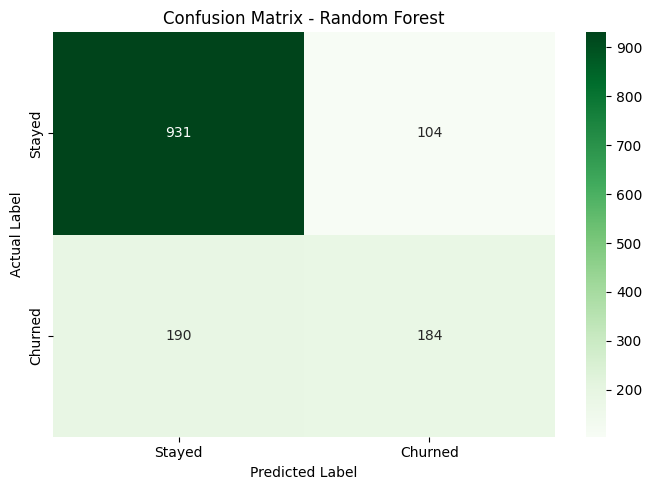

Confusion Matrix:
[[931 104]
 [190 184]]


In [8]:
# Generate confusion matrix
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=["Stayed", "Churned"],
    yticklabels=["Stayed", "Churned"]
)

plt.title("Confusion Matrix - Random Forest")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()
plt.show()

print("Confusion Matrix:")
print(cm)

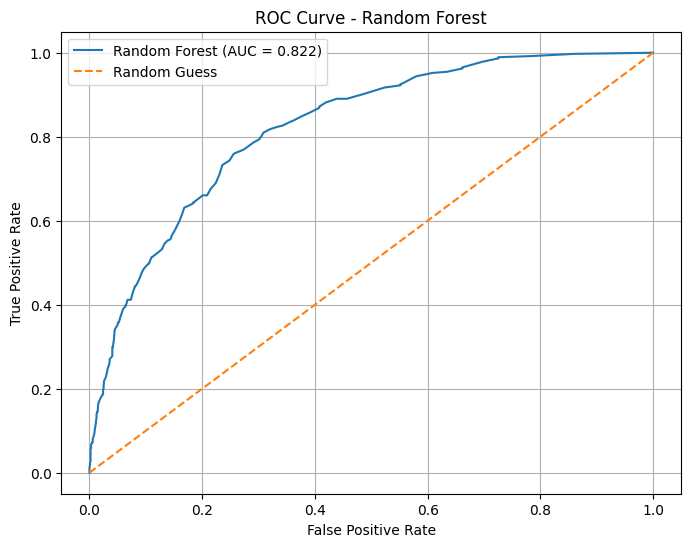

AUC Score: 0.8224


In [9]:
# Get prediction probabilities
y_prob = model.predict_proba(X_test)[:, 1]

# Calculate ROC curve
fpr, tpr, thresholds = roc_curve(y_test, y_prob)

# Calculate AUC score
auc_score = roc_auc_score(y_test, y_prob)

# Plot ROC curve
plt.figure(figsize=(8, 6))

plt.plot(fpr, tpr, label=f"Random Forest (AUC = {auc_score:.3f})")
plt.plot([0, 1], [0, 1], linestyle="--", label="Random Guess")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Random Forest")
plt.legend()
plt.grid()
plt.show()

print("AUC Score:", round(auc_score, 4))

In [10]:
# Calculate training and testing accuracy

train_accuracy = model.score(X_train, y_train)
test_accuracy = model.score(X_test, y_test)

print("Training Accuracy:", round(train_accuracy * 100, 2), "%")
print("Testing Accuracy:", round(test_accuracy * 100, 2), "%")

print("Accuracy Difference:", round(
    (train_accuracy - test_accuracy) * 100, 2
), "%")

Training Accuracy: 99.8 %
Testing Accuracy: 79.13 %
Accuracy Difference: 20.67 %


In [11]:
# Improved Random Forest Model

improved_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=10,
    min_samples_split=10,
    min_samples_leaf=5,
    class_weight="balanced",
    random_state=42
)

# Train improved model
improved_model.fit(X_train, y_train)

# Predictions
improved_pred = improved_model.predict(X_test)

# Evaluate improved model
print("Improved Model Results")
print("----------------------")
print("Accuracy:", round(accuracy_score(y_test, improved_pred) * 100, 2), "%")
print("Precision:", round(precision_score(y_test, improved_pred) * 100, 2), "%")
print("Recall:", round(recall_score(y_test, improved_pred) * 100, 2), "%")
print("F1 Score:", round(f1_score(y_test, improved_pred) * 100, 2), "%")

print("\nTraining Accuracy:",
      round(improved_model.score(X_train, y_train) * 100, 2), "%")

print("Testing Accuracy:",
      round(improved_model.score(X_test, y_test) * 100, 2), "%")

Improved Model Results
----------------------
Accuracy: 76.3 %
Precision: 53.69 %
Recall: 77.81 %
F1 Score: 63.54 %

Training Accuracy: 81.75 %
Testing Accuracy: 76.3 %


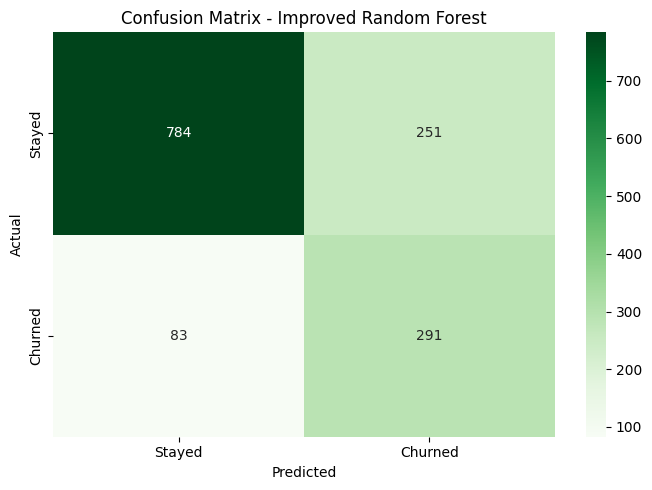

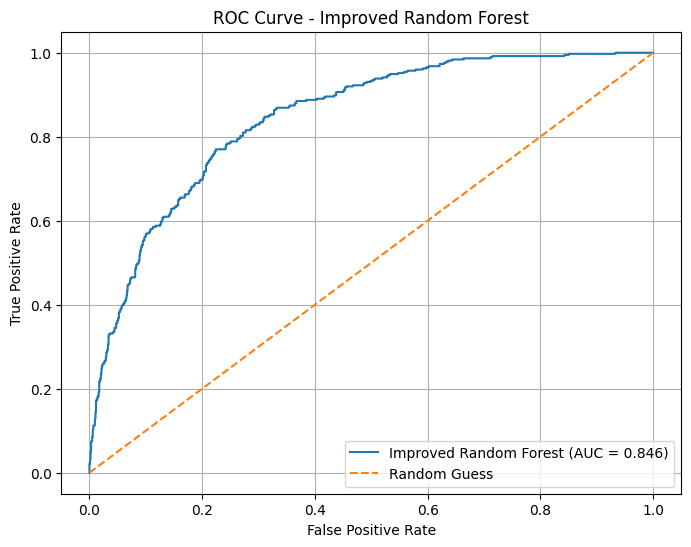

Improved Model AUC: 0.8456
Improved Confusion Matrix:
[[784 251]
 [ 83 291]]


In [16]:
# Improved model confusion matrix
improved_cm = confusion_matrix(y_test, improved_pred)

plt.figure(figsize=(7, 5))
sns.heatmap(
    improved_cm,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=["Stayed", "Churned"],
    yticklabels=["Stayed", "Churned"]
)

plt.title("Confusion Matrix - Improved Random Forest")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()

# Improved model ROC curve and AUC
improved_prob = improved_model.predict_proba(X_test)[:, 1]

fpr, tpr, thresholds = roc_curve(y_test, improved_prob)
improved_auc = roc_auc_score(y_test, improved_prob)

plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, label=f"Improved Random Forest (AUC = {improved_auc:.3f})")
plt.plot([0, 1], [0, 1], linestyle="--", label="Random Guess")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Improved Random Forest")
plt.legend()
plt.grid()
plt.show()

print("Improved Model AUC:", round(improved_auc, 4))
print("Improved Confusion Matrix:")
print(improved_cm)